### NLP

Branch of AI that enables computers to understand, analyze, and classify human language.

What does classifying textual data mean?

Assigning predefined labels or categories to text automatically based on its content.

## Load data

In [48]:
pip install scikit-learn

In [49]:
%pip install scikit-learn pandas matplotlib seaborn

In [50]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_20newsgroups

print("Libraries imported successfully!")

Libraries imported successfully!


In [51]:
from sklearn.datasets import fetch_20newsgroups

train_data = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

test_data = fetch_20newsgroups(
    subset="test",
    remove=("headers", "footers", "quotes")
)

print("Training documents:", len(train_data.data))
print("Testing documents:", len(test_data.data))
print("Number of categories:", len(train_data.target_names))
print(train_data.target_names)

Training documents: 11314
Testing documents: 7532
Number of categories: 20
['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


The dataset contains approximately 18,846 text documents across 20 categories. It is downloaded from a dataset archive hosted on Figshare, based on the original 20 Newsgroups collection.

In [52]:
# Load training data
train_data = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

# Load testing data
test_data = fetch_20newsgroups(
    subset="test",
    remove=("headers", "footers", "quotes")
)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [53]:
print("Training documents:", len(train_data.data))
print("Testing documents:", len(test_data.data))
print("Number of categories:", len(train_data.target_names))

Training documents: 11314
Testing documents: 7532
Number of categories: 20


In [54]:
# Display the first forum post
print(train_data.data[0])

# Display its category
print("\nCategory ID:", train_data.target[0])
print("Category name:",
      train_data.target_names[train_data.target[0]])

I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

Category ID: 7
Category name: rec.autos


Convert the data into a DataFrame

Makes the dataset easier to inspect and analyze.

In [55]:
train_df = pd.DataFrame({
    "text": train_data.data,
    "category_id": train_data.target,
    "category": [
        train_data.target_names[i]
        for i in train_data.target
    ]
})

test_df = pd.DataFrame({
    "text": test_data.data,
    "category_id": test_data.target,
    "category": [
        test_data.target_names[i]
        for i in test_data.target
    ]
})

print(train_df.head())
print("\nTraining dataset shape:", train_df.shape)
print("Testing dataset shape:", test_df.shape)

                                                text  category_id  \
0  I was wondering if anyone out there could enli...            7   
1  A fair number of brave souls who upgraded thei...            4   
2  well folks, my mac plus finally gave up the gh...            4   
3  \nDo you have Weitek's address/phone number?  ...            1   
4  From article <C5owCB.n3p@world.std.com>, by to...           14   

                category  
0              rec.autos  
1  comp.sys.mac.hardware  
2  comp.sys.mac.hardware  
3          comp.graphics  
4              sci.space  

Training dataset shape: (11314, 3)
Testing dataset shape: (7532, 3)


## Preprocess text

The goal is to clean the text, inspect its quality, understand category distribution, and convert posts into numerical features for machine learning.

Check for missing and empty posts.

In [56]:
# Check for missing values
print("Missing values:")
print(train_df.isnull().sum())

# Check for empty or whitespace-only posts
empty_posts = train_df["text"].fillna("").str.strip().eq("")

print("\nEmpty posts:", empty_posts.sum())
print("Total training posts:", len(train_df))

Missing values:
text           0
category_id    0
category       0
dtype: int64

Empty posts: 300
Total training posts: 11314


Remove empty posts

In [57]:
# Remove empty posts from training data
train_df = train_df.loc[
    ~train_df["text"].fillna("").str.strip().eq("")
].copy()

# Reset row indices
train_df.reset_index(drop=True, inplace=True)

print("Training data shape:", train_df.shape)

Training data shape: (11014, 3)


Category distribution

How many posts belong to each category.

In [58]:
category_counts = train_df["category"].value_counts()

print(category_counts)

category
comp.windows.x              591
soc.religion.christian      591
rec.sport.hockey            585
rec.motorcycles             583
sci.crypt                   582
sci.med                     578
comp.sys.ibm.pc.hardware    578
sci.space                   577
misc.forsale                577
rec.sport.baseball          575
sci.electronics             575
comp.graphics               571
comp.os.ms-windows.misc     568
rec.autos                   562
comp.sys.mac.hardware       558
talk.politics.mideast       549
talk.politics.guns          532
alt.atheism                 468
talk.politics.misc          453
talk.religion.misc          361
Name: count, dtype: int64


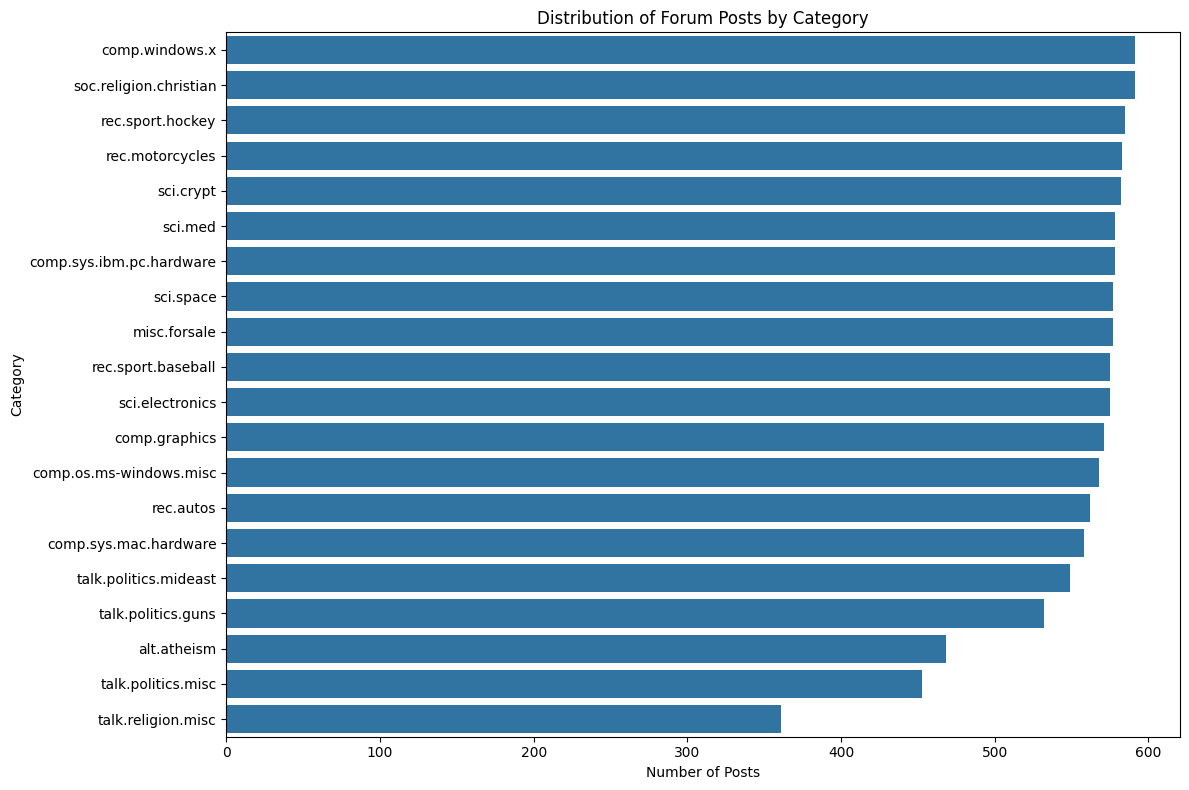

In [59]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 8))

sns.barplot(
    x=category_counts.values,
    y=category_counts.index
)

plt.title("Distribution of Forum Posts by Category")
plt.xlabel("Number of Posts")
plt.ylabel("Category")
plt.tight_layout()
plt.show()

Text length

In [60]:
# Calculate the number of characters in each post
train_df["text_length"] = train_df["text"].str.len()

# Summary statistics
print(train_df["text_length"].describe())

count    11014.000000
mean      1251.298075
std       4087.818670
min          3.000000
25%        253.250000
50%        507.000000
75%       1010.000000
max      74878.000000
Name: text_length, dtype: float64


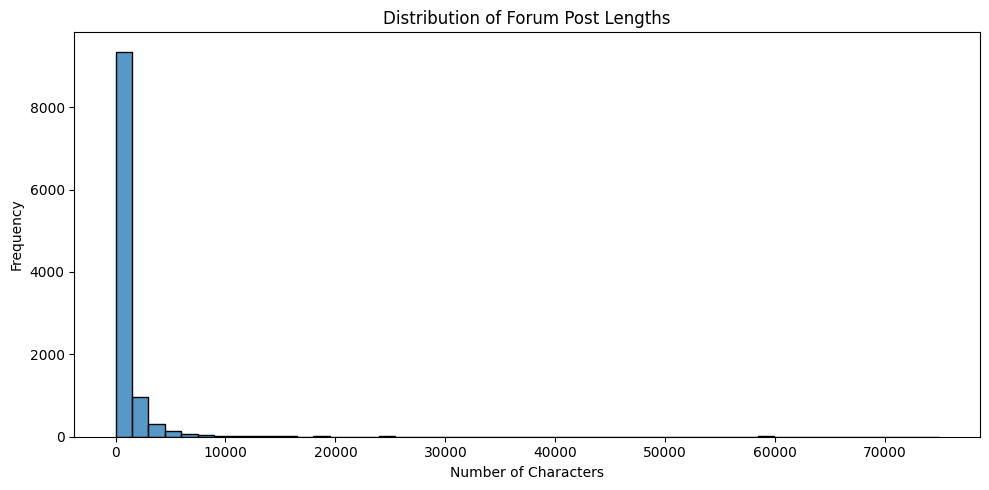

In [61]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=train_df,
    x="text_length",
    bins=50
)

plt.title("Distribution of Forum Post Lengths")
plt.xlabel("Number of Characters")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Heavy skew

In [62]:
# Calculate descriptive statistics
print(train_df["text_length"].describe())

# Calculate skewness
skewness = train_df["text_length"].skew()

print("\nSkewness:", skewness)

if skewness > 1:
    print("The distribution is highly right-skewed.")
elif skewness > 0.5:
    print("The distribution is moderately right-skewed.")
elif skewness < -1:
    print("The distribution is highly left-skewed.")
elif skewness < -0.5:
    print("The distribution is moderately left-skewed.")
else:
    print("The distribution has relatively low skewness.")


count    11014.000000
mean      1251.298075
std       4087.818670
min          3.000000
25%        253.250000
50%        507.000000
75%       1010.000000
max      74878.000000
Name: text_length, dtype: float64

Skewness: 11.003365387731016
The distribution is highly right-skewed.


The mean is about 2.47 times the median, suggesting that a relatively small number of very long posts pull the average upward.

TF-IDF

TF-IDF represents each post as a numerical vector based on the words and phrases it contains.

In [63]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    ngram_range=(1, 2)
)

# Learn vocabulary and transform training posts
X_train = tfidf.fit_transform(train_df["text"])

# Transform test posts using the training vocabulary
X_test = tfidf.transform(test_data.data)

# Extract target labels
y_train = train_df["category_id"].to_numpy()
y_test = test_data.target

print("Training feature matrix:", X_train.shape)
print("Testing feature matrix:", X_test.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))

Training feature matrix: (11014, 50000)
Testing feature matrix: (7532, 50000)
Vocabulary size: 50000


stop_words="english" removes common English words that often contribute little to classification.



max_features=50000 limits the vocabulary size.



ngram_range=(1, 2) considers both individual words and two-word phrases.



fit_transform() learns the vocabulary from the training data and transforms it.



transform() applies the same vocabulary and IDF weights to the test data.

## Train a classification model

Models:
1. Multinomial Naive Bayes
2. Logistic Regression
3. Linear Support Vector Machine (Linear SVM)

In [64]:
import time
import pandas as pd

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC

In [65]:
models = {
    "Multinomial Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    "Linear SVM": LinearSVC(
        random_state=42
    )
}

Naive Bayes: A fast baseline commonly used for text classification.



Logistic Regression: A linear classifier that often performs well with TF-IDF features.



Linear SVM: A strong candidate for text data with many features.

In [66]:
training_results = []

for name, model in models.items():
    start_time = time.time()

    # Train the model
    model.fit(X_train, y_train)

    # Measure training duration
    training_time = time.time() - start_time

    training_results.append({
        "Model": name,
        "Training Time (seconds)": round(training_time, 2)
    })

    print(f"{name} trained successfully!")
    print(f"Training time: {training_time:.2f} seconds\n")

training_df = pd.DataFrame(training_results)

print(training_df)

Multinomial Naive Bayes trained successfully!
Training time: 0.04 seconds

Logistic Regression trained successfully!
Training time: 12.82 seconds

Linear SVM trained successfully!
Training time: 0.81 seconds

                     Model  Training Time (seconds)
0  Multinomial Naive Bayes                     0.04
1      Logistic Regression                    12.82
2               Linear SVM                     0.81


## Evaluate the model

Metrics:
- Accuracy: Overall proportion of correctly classified posts.
- Precision: How often a model's category predictions are correct.
- Recall: How many posts belonging to a category the model identifies correctly.
- Macro F1-score: The average F1-score across all 20 categories, giving each category equal importance.

In [67]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

evaluation_results = []

for name, model in models.items():

    # Generate predictions using the test data
    y_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    macro_f1 = f1_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    evaluation_results.append({
        "Model": name,
        "Accuracy": round(accuracy, 4),
        "Macro Precision": round(precision, 4),
        "Macro Recall": round(recall, 4),
        "Macro F1": round(macro_f1, 4)
    })

# Create comparison table
results_df = pd.DataFrame(evaluation_results)

# Rank models by macro F1-score
results_df = results_df.sort_values(
    by="Macro F1", ascending=False
).reset_index(drop=True)

print("MODEL PERFORMANCE COMPARISON")
display(results_df)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Macro Precision,Macro Recall,Macro F1
0,Linear SVM,0.6884,0.6851,0.6768,0.6774
1,Logistic Regression,0.6880,0.6923,0.6741,0.6742
2,Multinomial Naive Bayes,0.6796,0.7400,0.6592,0.6515


Linear SVM is the best-performing model overall, although its advantage over Logistic Regression is very small.

The results suggest that the models correctly classify roughly 69% of test posts.

This is a reasonable baseline for a 20-category text-classification task, though there is room for improvement.

The next step is to determine which categories cause the most mistakes.

## Error analysis

Linear SVM to examine misclassified posts, identify categories that are commonly confused, and investigate possible reasons for the errors.

In [68]:
from sklearn.metrics import classification_report
import pandas as pd

# Select the best-performing model
best_model_name = results_df.iloc[0]["Model"]
best_model = models[best_model_name]

# Generate predictions
y_pred = best_model.predict(X_test)

# Create a dataframe for all test predictions
predictions_df = pd.DataFrame({
    "Text": test_data.data,
    "Actual Category": [
        test_data.target_names[i] for i in y_test
    ],
    "Predicted Category": [
        test_data.target_names[i] for i in y_pred
    ]
})

# Keep only incorrect predictions
errors_df = predictions_df[
    predictions_df["Actual Category"]
    != predictions_df["Predicted Category"]
].copy()

print("Selected model:", best_model_name)
print("Total test posts:", len(predictions_df))
print("Misclassified posts:", len(errors_df))
print(
    "Error rate:",
    round(len(errors_df) / len(predictions_df) * 100, 2),
    "%"
)

display(errors_df.head(10))


Selected model: Linear SVM
Total test posts: 7532
Misclassified posts: 2347
Error rate: 31.16 %


,Text,Actual Category,Predicted Category
0,I am a little confused on all of the models of...,rec.autos,comp.sys.mac.hardware
1,I'm not familiar at all with the format of the...,comp.windows.x,comp.graphics
2,"\nIn a word, yes.\n",alt.atheism,comp.os.ms-windows.misc
3,\nThey were attacking the Iraqis to drive them...,talk.politics.mideast,alt.atheism
6,"Dishonest money dwindles away, but he who gath...",soc.religion.christian,alt.atheism
7,A friend of mine managed to get a copy of a co...,soc.religion.christian,comp.os.ms-windows.misc
11,Most graphics systems I have seen have drawing...,comp.windows.x,comp.graphics
14,\nProbably because it IS rape.\n\n\nSo nothing...,alt.atheism,soc.religion.christian
15,"From article <C68uBG.K2w@world.std.com>, by cf...",comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware
16,Iv'e got a problem printing with a StyleWriter...,comp.sys.mac.hardware,comp.os.ms-windows.misc


Find the most frequently confused categories

In [69]:
from sklearn.metrics import confusion_matrix

# Create a confusion matrix
category_names = test_data.target_names

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=range(len(category_names))
)

# Extract incorrect category pairs
confusions = []

for actual_id in range(len(category_names)):
    for predicted_id in range(len(category_names)):

        if actual_id != predicted_id and cm[actual_id, predicted_id] > 0:
            confusions.append({
                "Actual Category": category_names[actual_id],
                "Predicted Category": category_names[predicted_id],
                "Number of Errors": cm[actual_id, predicted_id]
            })

confusions_df = pd.DataFrame(confusions)

confusions_df = confusions_df.sort_values(
    by="Number of Errors",
    ascending=False
).reset_index(drop=True)

print("TOP 10 CATEGORY CONFUSIONS")
display(confusions_df.head(10))


TOP 10 CATEGORY CONFUSIONS


,Actual Category,Predicted Category,Number of Errors
0,talk.politics.misc,talk.politics.guns,83
1,talk.religion.misc,soc.religion.christian,67
2,alt.atheism,soc.religion.christian,47
3,comp.windows.x,comp.graphics,46
4,comp.sys.ibm.pc.hardware,comp.os.ms-windows.misc,38
5,comp.os.ms-windows.misc,comp.sys.ibm.pc.hardware,38
6,comp.windows.x,comp.os.ms-windows.misc,38
7,alt.atheism,talk.religion.misc,30
8,soc.religion.christian,talk.religion.misc,29
9,comp.sys.mac.hardware,comp.sys.ibm.pc.hardware,29


In [70]:
# Display five misclassified posts with readable text
for index, row in errors_df.head(5).iterrows():
    print("ACTUAL CATEGORY:", row["Actual Category"])
    print("PREDICTED CATEGORY:", row["Predicted Category"])
    print("POST:")
    print(str(row["Text"])[:1000])
    print()


ACTUAL CATEGORY: rec.autos
PREDICTED CATEGORY: comp.sys.mac.hardware
POST:
I am a little confused on all of the models of the 88-89 bonnevilles.
I have heard of the LE SE LSE SSE SSEI. Could someone tell me the
differences are far as features or performance. I am also curious to
know what the book value is for prefereably the 89 model. And how much
less than book value can you usually get them for. In other words how
much are they in demand this time of year. I have heard that the mid-spring
early summer is the best time to buy.

ACTUAL CATEGORY: comp.windows.x
PREDICTED CATEGORY: comp.graphics
POST:
I'm not familiar at all with the format of these "X-Face:" thingies, but
after seeing them in some folks' headers, I've *got* to *see* them (and
maybe make one of my own)!

I've got "dpg-view" on my Linux box (which displays "uncompressed X-Faces")
and I've managed to compile [un]compface too... but now that I'm *looking*
for them, I can't seem to find any X-Face:'s in anyones news headers

Key limitations

Context loss: Short replies cannot be classified reliably without the surrounding conversation.



Similar categories: Closely related topics, such as computer systems and graphics, share vocabulary.



Mixed-topic posts: A single message can discuss politics, religion, and international affairs simultaneously.

## Route posts automatically

Define example routing rules that can later be adapted to a real organization.

In [71]:
# Map each predicted category to a support channel

routing_rules = {
    "alt.atheism": "Religion and Beliefs Support",
    "comp.graphics": "Graphics and Design Support",
    "comp.os.ms-windows.misc": "Windows Technical Support",
    "comp.sys.ibm.pc.hardware": "Computer Hardware Support",
    "comp.sys.mac.hardware": "Mac Hardware Support",
    "comp.windows.x": "Window Systems Support",
    "misc.forsale": "Marketplace Support",
    "rec.autos": "Automotive Support",
    "rec.motorcycles": "Motorcycle Support",
    "rec.sport.baseball": "Baseball Support",
    "rec.sport.hockey": "Hockey Support",
    "sci.crypt": "Cryptography Support",
    "sci.electronics": "Electronics Support",
    "sci.med": "Medical Information Support",
    "sci.space": "Space and Science Support",
    "soc.religion.christian": "Christianity Discussion Support",
    "talk.politics.guns": "Firearms Policy Discussion",
    "talk.politics.mideast": "Middle East Politics Support",
    "talk.politics.misc": "General Politics Support",
    "talk.religion.misc": "General Religion Discussion"
}

print("Routing rules created:", len(routing_rules))
print("Model categories:", len(test_data.target_names))


Routing rules created: 20
Model categories: 20


Each category has a destination. For example, a post classified as rec.autos will be sent to Automotive Support. These are prototype routing labels, not real departments.

Build the automatic routing function
This function will perform four operations:
1. Accept a new post.
2. Convert its text into TF-IDF features using the already-fitted vectorizer.
3. Predict the category using Linear SVM.
4. Return the predicted category and routing destination.

In [72]:
def route_post(post_text):
    # Validate the incoming post
    if not isinstance(post_text, str) or not post_text.strip():
        return {
            "post": post_text,
            "predicted_category": None,
            "destination": "Manual Review",
            "status": "Invalid or empty post"
        }

    # Convert text into TF-IDF features
    post_vector = tfidf.transform([post_text])

    # Predict category using the trained Linear SVM
    predicted_id = best_model.predict(post_vector)[0]

    # Convert category ID to category name
    predicted_category = test_data.target_names[predicted_id]

    # Find the appropriate destination
    destination = routing_rules.get(
        predicted_category,
        "General Support"
    )

    return {
        "post": post_text,
        "predicted_category": predicted_category,
        "destination": destination,
        "status": "Routed"
    }


TEst it

In [73]:
sample_posts = [
    "My car engine makes a strange noise when I accelerate. What should I check?",
    "How can I install a new graphics card in my desktop computer?",
    "What are the main causes of political conflict in the Middle East?"
]

for post in sample_posts:
    result = route_post(post)
    print("POST:", result["post"])
    print("PREDICTED CATEGORY:", result["predicted_category"])
    print("ROUTED TO:", result["destination"])
    print("STATUS:", result["status"])


POST: My car engine makes a strange noise when I accelerate. What should I check?
PREDICTED CATEGORY: rec.autos
ROUTED TO: Automotive Support
STATUS: Routed
POST: How can I install a new graphics card in my desktop computer?
PREDICTED CATEGORY: comp.graphics
ROUTED TO: Graphics and Design Support
STATUS: Routed
POST: What are the main causes of political conflict in the Middle East?
PREDICTED CATEGORY: talk.politics.mideast
ROUTED TO: Middle East Politics Support
STATUS: Routed


In [74]:
new_post = """
I am having problems connecting my computer to the internet.
The network adapter is not working correctly.
"""

result = route_post(new_post)

print("PREDICTED CATEGORY:", result["predicted_category"])
print("DESTINATION:", result["destination"])
print("STATUS:", result["status"])


PREDICTED CATEGORY: misc.forsale
DESTINATION: Marketplace Support
STATUS: Routed


Test was succesful

In [75]:
routing_correct = 0
routing_total = len(test_data.data)

for text, actual_id in zip(test_data.data, y_test):
    result = route_post(text)

    actual_category = test_data.target_names[actual_id]

    if result["predicted_category"] == actual_category:
        routing_correct += 1

routing_accuracy = routing_correct / routing_total

print("Total posts tested:", routing_total)
print("Correctly routed posts:", routing_correct)
print(f"Routing accuracy: {routing_accuracy:.2%}")


Total posts tested: 7532
Correctly routed posts: 5171
Routing accuracy: 68.65%


The system automatically assigns posts to channels based on the category predicted by Linear SVM.

However, approximately 31.35% of test posts were assigned to the wrong category and therefore potentially to the wrong channel.

In [76]:
def route_post(post_text):
    # Handle empty or invalid input
    if not isinstance(post_text, str) or not post_text.strip():
        return {
            "post": post_text,
            "predicted_category": None,
            "destination": "Manual Review",
            "status": "Invalid or empty post"
        }

    # Convert the post using the fitted TF-IDF vectorizer
    post_vector = tfidf.transform([post_text])

    # Predict category
    predicted_id = best_model.predict(post_vector)[0]
    predicted_category = test_data.target_names[predicted_id]

    # Select destination
    destination = routing_rules.get(
        predicted_category,
        "General Support"
    )

    return {
        "post": post_text,
        "predicted_category": predicted_category,
        "destination": destination,
        "status": "Routed"
    }


In [77]:
from sklearn.metrics import accuracy_score

routed_predictions = []

for post in test_data.data:
    result = route_post(post)

    if result["predicted_category"] is None:
        # Invalid posts cannot be assigned a predicted category
        routed_predictions.append(-1)
    else:
        predicted_id = test_data.target_names.index(
            result["predicted_category"]
        )
        routed_predictions.append(predicted_id)

# Direct model predictions
direct_predictions = best_model.predict(X_test)

# Compare predictions
print(
    "Predictions match:",
    (direct_predictions == routed_predictions).all()
)

# Compare accuracy
direct_accuracy = accuracy_score(y_test, direct_predictions)

valid_predictions = [
    pred for pred in routed_predictions if pred != -1
]
valid_actual = [
    actual
    for actual, pred in zip(y_test, routed_predictions)
    if pred != -1
]

routing_accuracy_check = accuracy_score(
    valid_actual, valid_predictions
)

print(f"Direct model accuracy: {direct_accuracy:.4%}")
print(f"Routing accuracy:      {routing_accuracy_check:.4%}")
print("Valid posts:", len(valid_predictions))
print("Invalid posts:", len(routed_predictions) - len(valid_predictions))


Predictions match: False
Direct model accuracy: 68.8396%
Routing accuracy:      70.6710%
Valid posts: 7317
Invalid posts: 215


215 test posts are being treated as invalid by route_post(), so they are excluded from the routing accuracy calculation.

This explains why the routing accuracy is higher than the direct model accuracy.

In [78]:
# Count empty or whitespace-only test posts
empty_test_mask = [
    not isinstance(post, str) or not post.strip()
    for post in test_data.data
]

print("Total test posts:", len(test_data.data))
print("Empty/invalid posts:", sum(empty_test_mask))

# Inspect a few invalid posts
for i, post in enumerate(test_data.data):
    if empty_test_mask[i]:
        print(f"Index {i}: {repr(post)}")
        if i >= 10:
            break


Total test posts: 7532
Empty/invalid posts: 215
Index 87: ''


In [79]:
valid_indices = [
    i for i, post in enumerate(test_data.data)
    if isinstance(post, str) and post.strip()
]

direct_valid = best_model.predict(X_test[valid_indices])

routed_valid = []

for i in valid_indices:
    result = route_post(test_data.data[i])
    predicted_category = result["predicted_category"]

    predicted_id = test_data.target_names.index(predicted_category)
    routed_valid.append(predicted_id)

import numpy as np

matches = np.array(direct_valid) == np.array(routed_valid)

print("Valid posts:", len(valid_indices))
print("Matching predictions:", matches.sum())
print("Mismatching predictions:", (~matches).sum())
print("Predictions match:", matches.all())


Valid posts: 7317
Matching predictions: 7317
Mismatching predictions: 0
Predictions match: True


- 68.84% classification accuracy: Linear SVM correctly classified approximately 69% of all test posts.
- 100% prediction agreement on valid posts: The routing function and direct model predictions match on all 7,317 valid posts.
- 215 invalid posts: These were not classified because they were empty or contained only whitespace. They were sent to manual review by the routing function.

Note that 100% prediction agreement means the routing function consistently uses the classifier's predictions.

In [80]:
from sklearn.metrics import accuracy_score
import numpy as np

valid_indices = [
    i for i, post in enumerate(test_data.data)
    if isinstance(post, str) and post.strip()
]

valid_actual = y_test[valid_indices]
valid_predictions = np.array(routed_valid)

valid_accuracy = accuracy_score(
    valid_actual, valid_predictions
)

print("Valid posts:", len(valid_indices))
print(f"Accuracy on valid posts: {valid_accuracy:.4%}")
print(f"Accuracy on full test set: {accuracy_score(y_test, best_model.predict(X_test)):.4%}")


Valid posts: 7317
Accuracy on valid posts: 70.6710%
Accuracy on full test set: 68.8396%


# Evaluation of the Automatic Routing System

The automatic routing system was evaluated using the 20 Newsgroups test dataset, containing 7,532 posts. Of these, 7,317 contained valid text, while 215 were empty or contained only whitespace.

The Linear Support Vector Machine classifier achieved an accuracy of 68.84% on the complete test set and 70.67% when evaluation was restricted to valid posts. The difference reflects the exclusion of empty posts from the valid-post evaluation.

Verification of the routing function showed 100% agreement between its predictions and those generated directly by the trained classifier for all 7,317 valid posts. This confirms that the routing implementation correctly applies the model's predictions. However, prediction agreement should not be confused with classification accuracy, since the classifier can consistently assign an incorrect category.

Overall, the results demonstrate that automated text classification can support category-based forum post routing. Nevertheless, the model still misclassifies a proportion of posts, highlighting the need for further improvements before deployment in a real-world environment. Empty posts are handled through manual review to prevent invalid inputs from being automatically assigned to inappropriate channels.

In [83]:
%cd /content
!git clone https://github.com/SirTEdgar/Analytics-Firm-Clients.git


/content
Cloning into 'Analytics-Firm-Clients'...
remote: Enumerating objects: 6, done.
remote: Counting objects: 100% (6/6), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 6 (delta 0), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (6/6), done.


In [85]:
%cd /content/Analytics-Firm-Clients
!git status
!git log -1 --oneline

/content/Analytics-Firm-Clients
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
f803207 (HEAD -> main, origin/main, origin/HEAD) Enhance README with project overview and notebook details


In [86]:
%cd /content/Analytics-Firm-Clients
!ls -la

/content/Analytics-Firm-Clients
total 16
drwxr-xr-x 3 root root 4096 Oct 11 09:06 .
drwxr-xr-x 1 root root 4096 Oct 11 09:06 ..
drwxr-xr-x 8 root root 4096 Oct 11 09:09 .git
-rw-r--r-- 1 root root 1410 Oct 11 09:06 README.md
